# Create Bubble Plots Using Output Files from Ingenuity Pathway Analysis

In [1]:
library(data.table)
library(dplyr)
library(ggplot2)
library(svglite)

Warning message:
“package ‘data.table’ was built under R version 4.3.3”
Warning message:
“package ‘dplyr’ was built under R version 4.3.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## Pathways from Srf d/d and PRKO shared DEG list

In [2]:
relevant_pws_srf_prko <- fread("PRcreSrf-AND-PRKO-overlap-same-dir-FC-Pathways.csv")
relevant_pws_srf_prko$Category <- as.factor(relevant_pws_srf_prko$Category)
relevant_pws_srf_prko <- relevant_pws_srf_prko %>% group_by(Category) %>% arrange(desc(zScore), .by_group = TRUE)
head(relevant_pws_srf_prko, 10)

Ingenuity Canonical Pathways,Category,-log(p-value),zScore,Ratio,Molecules
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<chr>
Mitochondrial Dysfunction,Cell stress,1.50,1.633,0.0205,"Atp1a2,BCL2,CACNA1C,GPX3,IDH2,MAOB,PIK3R3"
Integration of energy metabolism,Cell stress,3.42,-2.449,0.0556,"ADCY5,CACNA1C,GNAI1,GNG2,PLCB1,PRKCA"
Protein Ubiquitination Pathway,Cell stress,1.44,-2.449,0.0216,"B2M,CRYAB,DNAJB5,HSPB7,SACS,USP54"
RHOGDI Signaling,G-proteins,7.09,1.890,0.0591,"ACTA2,ACTG2,GNAI1,GNG2,ITGA1,ITGA7,ITGB1,ITGB5,MYH11,MYL9,PPP1R12C,PRKCA,RHOJ"
G Beta Gamma Signaling,G-proteins,3.82,-2.449,0.0538,"CACNA1C,CAV1,GNAI1,GNG2,PRKCA,RASD2,RRAS"
Ephrin Receptor Signaling,G-proteins,5.74,-2.646,0.0545,"ABL1,GNAI1,GNG2,ITGA1,ITGA7,ITGB1,ITGB5,RASD2,RRAS,SORBS1,WIPF1"
PTEN Signaling,Growth and prolif,6.03,2.236,0.0662,"BCL2,ILK,ITGA1,ITGA7,ITGB1,ITGB5,PIK3R3,RASD2,RRAS,TGFBR3"
Estrogen Receptor Signaling,Growth and prolif,4.10,-2.887,0.0315,"ADCY5,BCL2,CACNA1C,CAV1,GNAI1,GNG2,MYL9,PGR,PIK3R3,PLCB1,PRKCA,RASD2,RRAS"
Molecular Mechanisms of Cancer,Growth and prolif,3.21,-3.771,0.0209,"ABL1,ADCY5,ADCYAP1R1,BCL2,GNAI1,GNG2,IL13RA2,ITGA1,ITGA7,ITGB1,ITGB5,MAPK11,PIK3R3,PLCB1,PRKCA,RASD2,RHOJ,RRAS"


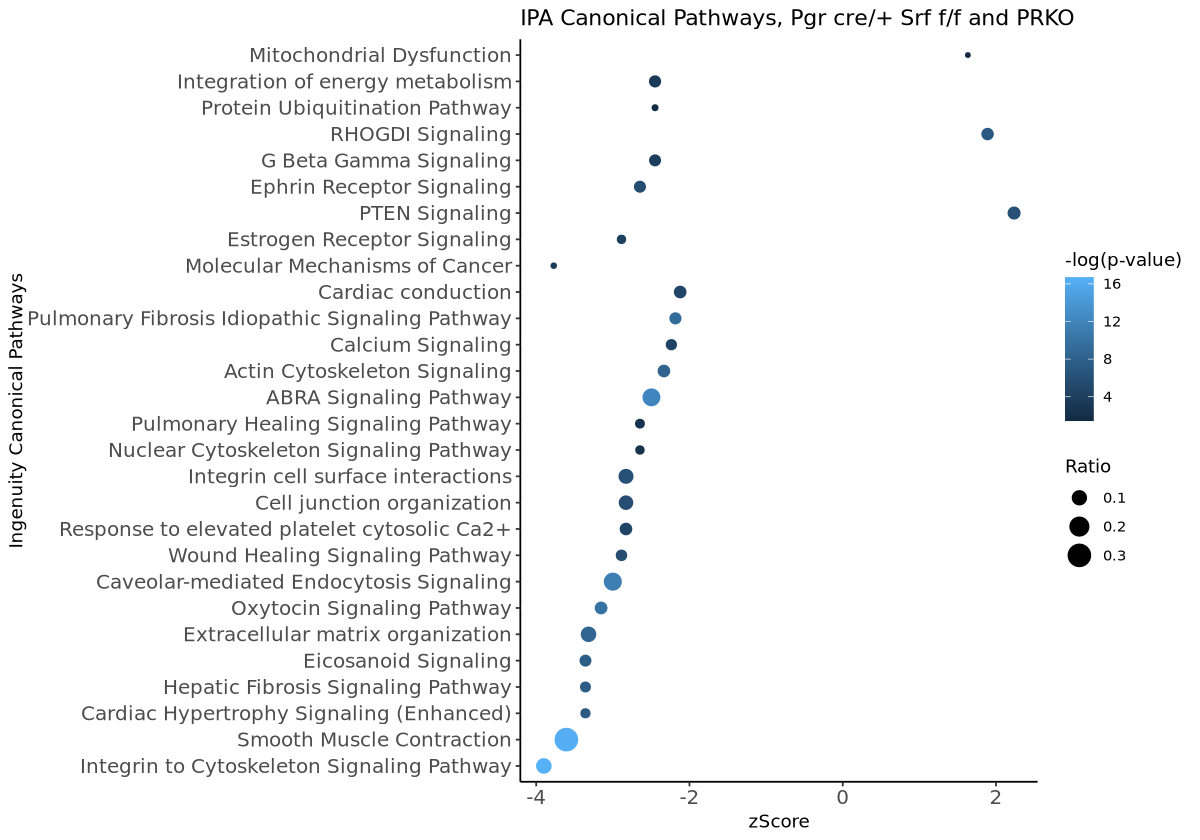

In [3]:
## Make dot plots for GO terms.

# Make the function for GO plots. See the Github link above.
# Code taken from enrichplot: https://github.com/YuLab-SMU/enrichplot/blob/devel/R/dotplot.R#L200-L207
ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = `Ingenuity Canonical Pathways`,
                      x = zScore,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_bw() +  theme(axis.line = element_line(colour = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    panel.border = element_blank(),
    panel.background = element_blank(),
                                                                                    axis.text=element_text(size=12)) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10)
ipa_plot(relevant_pws_srf_prko, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and PRKO")
options(saved)

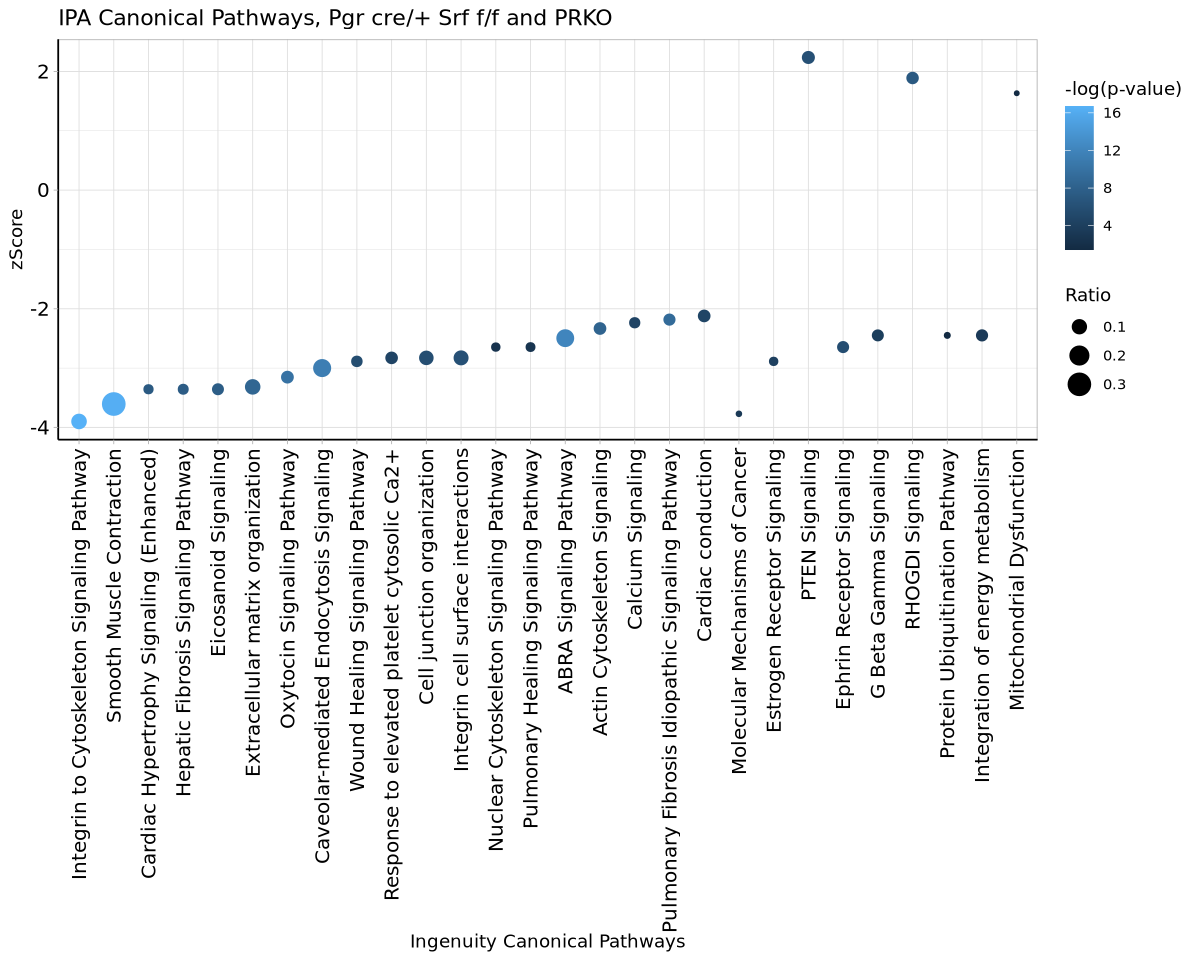

In [4]:
# Modify the layout and theme

ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = zScore,
                      x = `Ingenuity Canonical Pathways`,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_light() +  theme(axis.line = element_line(colour = "black"),
    #panel.grid.major = element_blank(),
    #panel.grid.minor = element_blank(),
    #panel.border = element_blank(),
    #panel.background = element_blank(),
                axis.text.x=element_text(angle=90, hjust=1, vjust=0.5),
                axis.text=element_text(size=12, color="black")) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10, repr.plot.height = 8)
ipa_plot(relevant_pws_srf_prko, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and PRKO")
options(saved)

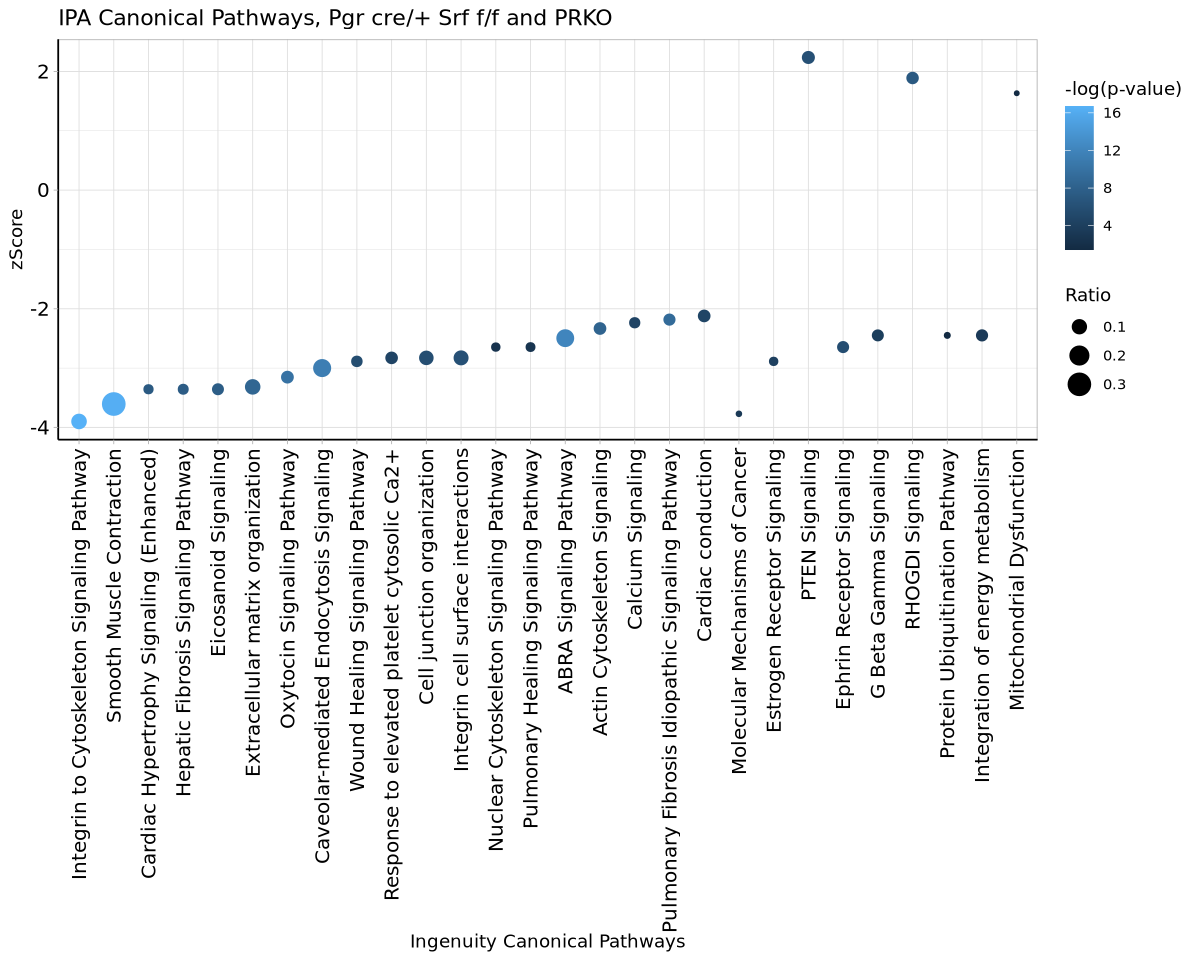

In [5]:
#Now we can just run the function again to reproduce the same parameters
saved <- options(repr.plot.width = 10, repr.plot.height = 8)
ipa_plot(relevant_pws_srf_prko, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and PRKO")
options(saved)

In [8]:
# Save plot as SVG

my_plot <- ipa_plot(relevant_pws_srf_prko, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and PRKO")

    
ggsave(filename = "251202_Srf_PRKO_IPA.svg", plot = my_plot, 
           width = 10, height = 8, units = "in") 

## Pathways from Srf d/d full DEG list

In [9]:
relevant_pws_srf <- fread("PRcreSrf-Pathways.csv")
relevant_pws_srf$Category <- as.factor(relevant_pws_srf$Category)
relevant_pws_srf <- relevant_pws_srf %>% group_by(Category) %>% arrange(desc(zScore), .by_group = TRUE)
head(relevant_pws_srf, 10)

Ingenuity Canonical Pathways,Category,-log(p-value),zScore,Ratio,Molecules
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<chr>
SRP-dependent cotranslational protein targeting to membrane,Cell stress,1.77,3.050851,0.113,"Arxes1/Arxes2,DDOST,RPL10A,RPLP2,RPN1,RPN2,SEC11C,SEC61A1,SEC61B,SPCS2,SPCS3,SSR1,SSR3"
Unfolded protein response,Cell stress,3.15,3.000000,0.156,"BCL2,CALR,CANX,DNAJB11,DNAJB14,DNAJB5,DNAJB9,HSP90B1,HSPA5,P4HB,PDIA6,SREBF1,VCP,XBP1"
XBP1(S) activates chaperone genes,Cell stress,4.10,2.713602,0.229,"CTDSP2,DNAJB11,DNAJB9,HYOU1,MYDGF,PDIA5,PDIA6,SEC31A,SSR1,WFS1,XBP1"
COPII-mediated vesicle transport,Cell stress,2.53,2.713602,0.153,"AREG,BET1,COL7A1,F5,LMAN1,SCFD1,SEC31A,TFG,TMED10,TMED2,USO1"
Apoptosis Signaling,Cell stress,1.74,2.529822,0.115,"AIFM1,BCL2,CAPN6,CYCS,MAP2K4,NFKB2,NFKBIA,PLCG1,PRKCA,RASD1,RASD2,RRAS"
Endoplasmic Reticulum Stress Pathway,Cell stress,1.50,2.000000,0.190,"CALR,HSP90B1,HSPA5,XBP1"
RHOGDI Signaling,G-proteins,11.00,2.293659,0.191,"ACTA1,ACTA2,ACTB,ACTG1,ACTG2,CDH11,CDH13,CDH3,CDH4,DGKZ,EZR,FNBP1,GNA14,GNAI1,GNAO1,GNAQ,GNB2,GNG12,GNG2,GNG5,ITGA1,ITGA6,ITGA7,ITGB1,ITGB5,ITGB6,ITGB7,MYH10,MYH11,MYH9,MYL6,MYL9,MYO10,MYO1A,PIP5K1B,PPP1R12A,PPP1R12C,PRKCA,RHOC,RHOJ,RHOV,ROCK2"
G?q Signaling,G-proteins,6.72,-3.674235,0.171,"AGTR1,ARHGEF25,CHRM3,FNBP1,GNA14,GNAI1,GNAO1,GNAQ,GNB2,GNG12,GNG2,GNG5,ITPR2,NFATC2,NFATC4,NFKB2,NFKBIA,PIK3CG,PIK3R1,PIK3R3,PLCB1,PLCB4,PLCG1,PRKCA,PRKCB,RHOC,RHOJ,RHOV,ROCK2"
G-Protein Coupled Receptor Signaling,G-proteins,9.45,-4.146140,0.119,"ACKR3,ACKR4,ADCY1,ADCY2,ADCY5,ADCY8,ADCYAP1R1,ADGRA2,ADGRD1,AGTR1,APEX1,ARRB1,CAMK2A,CCR2,CHRM3,CREB3L4,CREB5,CTNNB1,EYA2,F2RL1,FICD,FOXO4,FZD10,FZD2,GNA14,GNAI1,GNAO1,GNAQ,GNB2,GNG12,GNG2,GNG5,GPR137C,GPR146,GPR161,GPR83,GRK3,JUN,KCNH2,KCNN3,KCNQ3,MAP2K4,MAP3K6,MAP3K9,MAPK11,MEGF6,MPPED2,MYL6,MYL9,MYLK,NFATC2,NFATC4,NFKB2,NFKBIA,NMUR2,NPY2R,PDE3A,PDE5A,PDE7A,PDE9A,PIK3CG,PIK3R1,PIK3R3,PLCB1,PLCB4,PLCG1,PRKAR2A,PRKCA,PRKCB,PTGER2,PTGER3,RAPGEF3,RAPGEF4,RASD1,RASD2,ROCK2,RRAS,SIX4,SRF,SSTR2,TBXA2R,TSHR,TULP2,WWTR1"


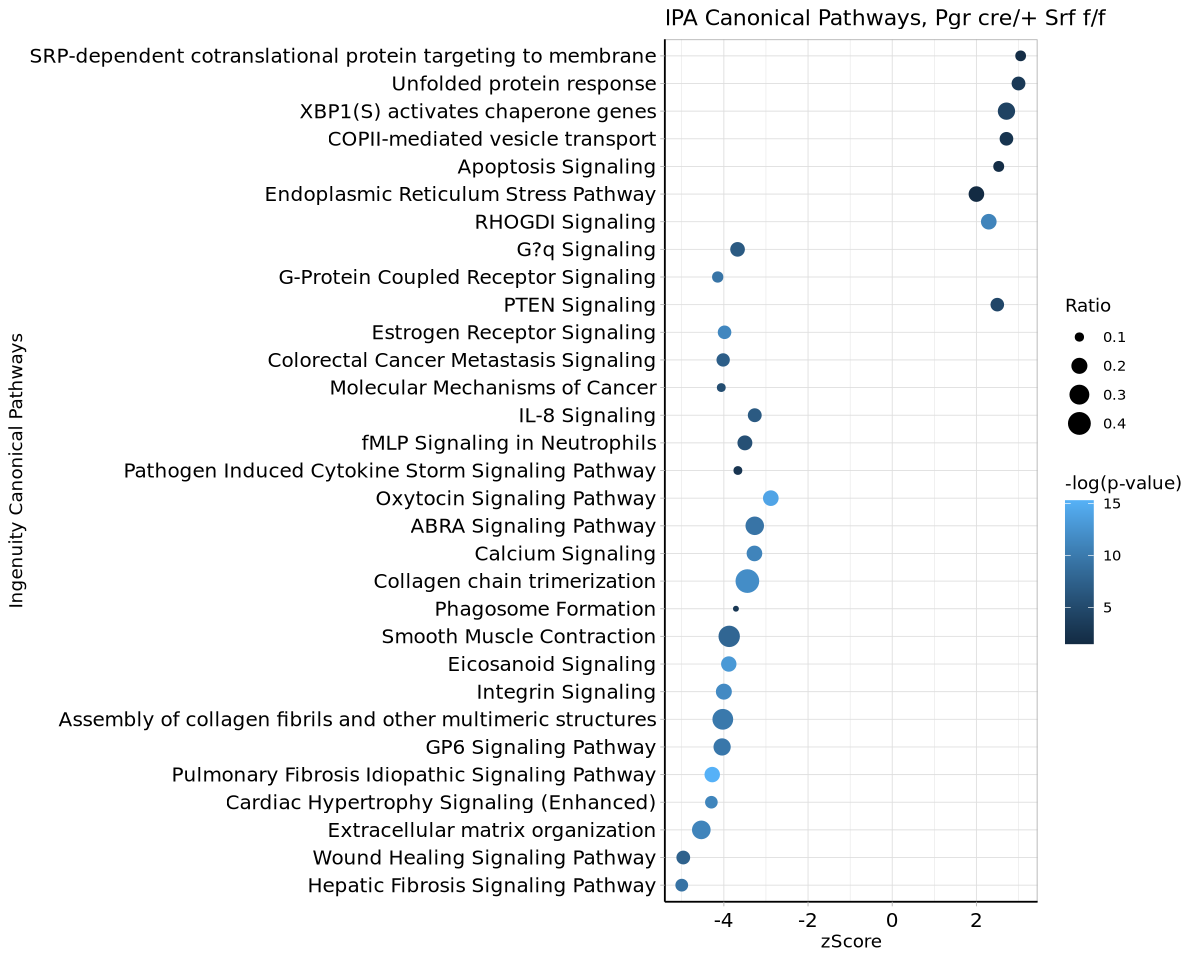

In [12]:
# Want to go back to vertical orientation for this one
ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = `Ingenuity Canonical Pathways`,
                      x = zScore,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_light() +  theme(axis.line = element_line(colour = "black"),
    #panel.grid.major = element_blank(),
    #panel.grid.minor = element_blank(),
    #panel.border = element_blank(),
    #panel.background = element_blank(),
                axis.text.x=element_text(angle=0, hjust=0.5, vjust=0.5),
                axis.text=element_text(size=12, color="black")) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10, repr.plot.height = 8)
ipa_plot(relevant_pws_srf, "IPA Canonical Pathways, Pgr cre/+ Srf f/f")
options(saved)

In [16]:
# Save plot as SVG

my_plot <- ipa_plot(relevant_pws_srf, "IPA Canonical Pathways, Pgr cre/+ Srf f/f")

    
ggsave(filename = "251203_Srf_IPA.svg", plot = my_plot, 
           width = 10, height = 6, units = "in") 

## Pathways from MyoPgr d/d and PRKO shared DEG list

In [19]:
relevant_pws_MyoPgrdd_prko <- fread("Myh11Pgr-AND-PRKO-overlap-same-dir-FC-Pathways.csv")
relevant_pws_MyoPgrdd_prko$Category <- as.factor(relevant_pws_MyoPgrdd_prko$Category)
relevant_pws_MyoPgrdd_prko <- relevant_pws_MyoPgrdd_prko %>% group_by(Category) %>% arrange(desc(zScore), .by_group = TRUE)
head(relevant_pws_MyoPgrdd_prko, 10)

Ingenuity Canonical Pathways,Category,-log(p-value),zScore,Ratio,Molecules
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<chr>
Mitochondrial Dysfunction,Cell stress,1.77,0.447,0.0146,"BCL2,CACNA1D,MAOB,NDUFA8,PRKAB2"
G-Protein Coupled Receptor Signaling,G-proteins,3.55,1.265,0.0154,"ADRA1A,CALCRL,GRM7,MYLK,OXTR,P2RY14,PDE5A,RGS2,RXFP2,SYNGAP1,WWTR1"
NF1 RAS Signaling Pathway,G-proteins,2.03,1.134,0.0130,"ADRA1A,CALCRL,GRM7,OXTR,P2RY14,PDGFRB,RXFP2"
Signaling by Rho Family GTPases,G-proteins,2.95,0.000,0.0225,"ACTG2,DES,ITGA1,ITGA8,MYLK,WASF1"
Neutrophil Extracellular Trap Signaling Pathway,Inflammatory,2.68,1.890,0.0171,"COL11A1,COL12A1,COL25A1,COL4A5,COL4A6,NDUFA8,PADI4"
Pathogen Induced Cytokine Storm Signaling Pathway,Inflammatory,2.85,-0.378,0.0183,"ADRA1A,COL11A1,COL12A1,COL25A1,COL4A5,COL4A6,CXCL16"
IL-4 Signaling,Inflammatory,1.40,-1.633,0.0104,"ANO1,COL11A1,COL12A1,COL25A1,COL4A5,COL4A6"
Oxytocin Signaling Pathway,Muscle-ECM-Cytoskeleton,2.79,-0.816,0.0209,"ATP2B4,CACNA1D,MYH11,MYLK,OXTR,PRKAB2"
Wound Healing Signaling Pathway,Muscle-ECM-Cytoskeleton,3.96,-1.134,0.0281,"COL11A1,COL12A1,COL25A1,COL4A5,COL4A6,LAMA1,LAMB3"


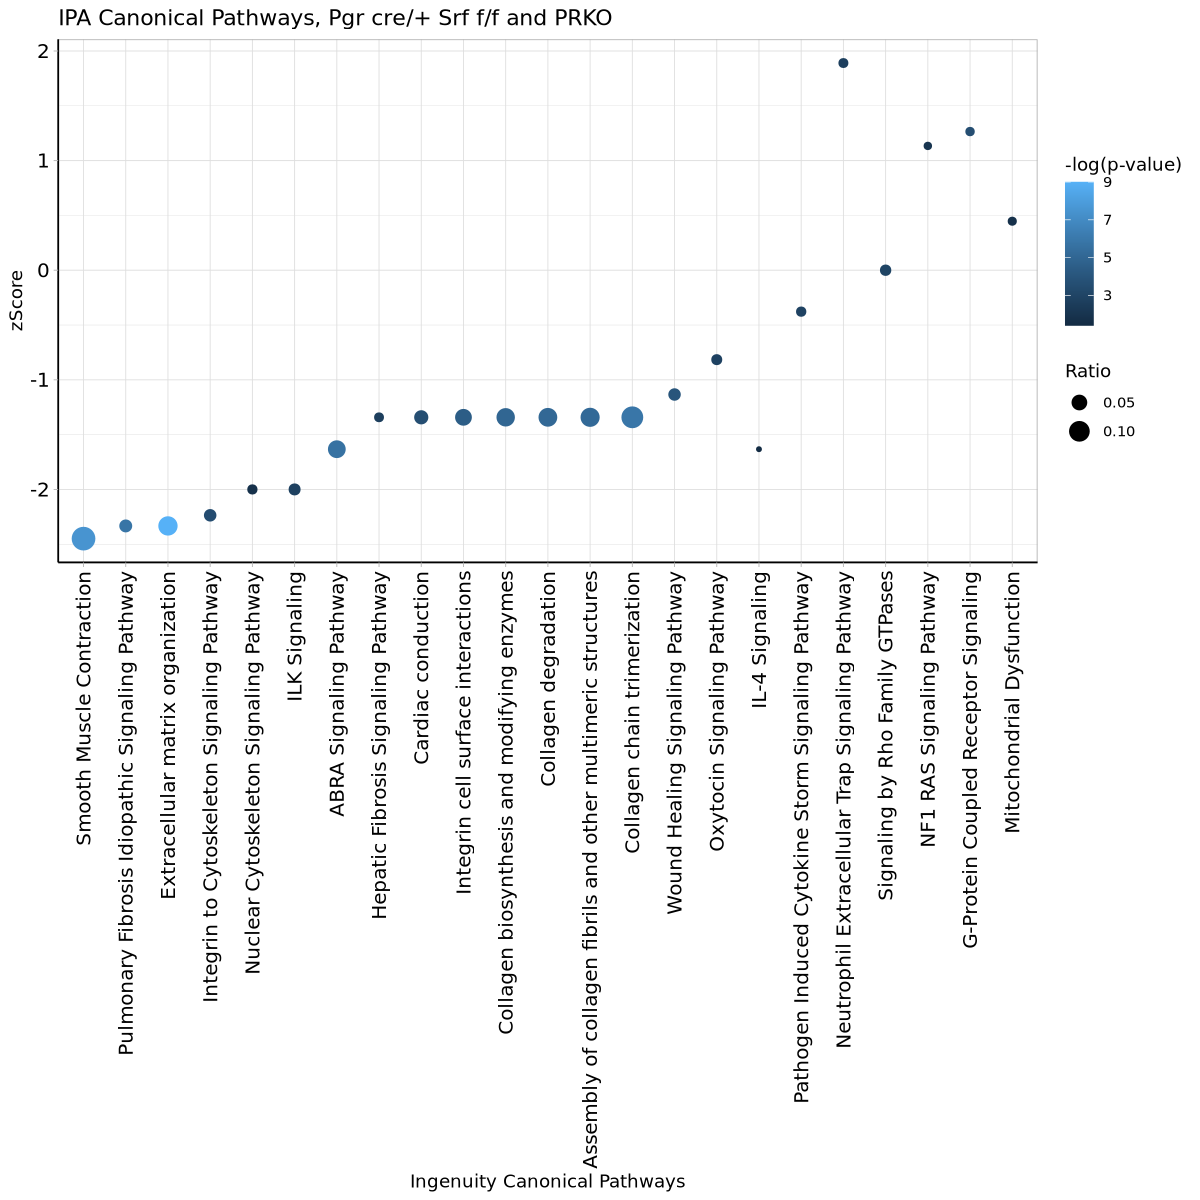

In [21]:
# Test plot

ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = zScore,
                      x = `Ingenuity Canonical Pathways`,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_light() +  theme(axis.line = element_line(colour = "black"),
    #panel.grid.major = element_blank(),
    #panel.grid.minor = element_blank(),
    #panel.border = element_blank(),
    #panel.background = element_blank(),
                axis.text.x=element_text(angle=90, hjust=1, vjust=0.5),
                axis.text=element_text(size=12, color="black")) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10, repr.plot.height = 10)
ipa_plot(relevant_pws_MyoPgrdd_prko, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and PRKO")
options(saved)

In [23]:
# Save plot as SVG

my_plot <- ipa_plot(relevant_pws_MyoPgrdd_prko, "IPA Canonical Pathways, Myh11 cre/+ Pgr f/f and PRKO")

    
ggsave(filename = "251203_MyoPgrdd-PRKO_IPA.svg", plot = my_plot, 
           width = 10, height = 9, units = "in") 

In [24]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /ddn/gs1/home/marquardtrm/miniforge3/envs/r431/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] svglite_2.2.2     ggplot2_4.0.1     dplyr_1.1.4       data.table_1.17.8

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.6.5        cli_3.6.5          rlang_1.1.6  